# Industry Project: Support Ticket Routing (Production-Style)

> **Who is this notebook for?** Someone who has never shipped an NLP model to real users.
> You do **not** need the math from the other notebooks in `07_NLP/`. Every step is explained in plain English, and almost every line of code has a comment.

---

### How this notebook is different from `03_text_classification.ipynb`

| `03_text_classification.ipynb` (theory) | This notebook (industry) |
|---|---|
| Explains **how** TF-IDF, TextCNN, BiLSTM, BERT, zero-shot and SetFit work | Shows **how a company picks one and runs it** for real customers |
| Clean benchmark data | Messy tickets: personal data (emails, phone numbers, card numbers), HTML, duplicates, empty and huge texts, wrong labels |
| Stops at accuracy / F1 | Adds **latency, cost, confidence thresholds with a human fallback, explanations, saving, serving, monitoring and tests** |

---

### The business problem

You work at **"VoltCart"**, an online shop for computers and electronics. Customers write ~**40,000 support tickets per month** (web form, e-mail, chat).
Today a team of "triage agents" reads every ticket and forwards it to one of **six specialist teams**:

| Team | Handles |
|---|---|
| `hardware_support` | PC / Mac hardware: disks, RAM, monitors, SCSI, motherboards |
| `software_support` | Windows, drivers, X11 / Linux desktop problems |
| `graphics_and_display` | 3D graphics, image formats, rendering software |
| `sales_and_orders` | Buying, selling, prices, shipping, used items |
| `security_and_privacy` | Encryption, account security, privacy questions |
| `electronics_repair` | Circuits, power supplies, components, repairs |

**Costs (from the support operations team):**
- Manual triage costs about **\$2 per ticket** (1 minute of an agent).
- A **wrong** automatic route costs about **\$8** (the ticket bounces between teams, the customer waits longer, and satisfaction drops).

**Your job:** build a model that routes tickets automatically, **but only when it is confident**; uncertain tickets still go to a human. Success = lower total cost than "humans triage everything", with an auto-routed accuracy of at least ~90%.

> **Where does the data come from?** Real ticket data is private, so we use a public stand-in: posts from the **20 Newsgroups** dataset (real people asking real technical questions in 1993), mapped to VoltCart team names. We then add the mess that real ticket systems contain. The techniques are exactly the same as on a Zendesk / Jira / Salesforce export.

---

### Table of Contents
1. Setup: imports and one central config
2. Get the data: a realistic ticket export
3. First look at the data
4. Clean the text and mask personal data (PII)
5. Remove duplicates and junk, then split honestly
6. Baselines: dummy and TF-IDF + linear model
7. A transformer: sentence embeddings + logistic regression
8. Compare quality, speed and cost
9. Error analysis: where does the model fail?
10. Confidence threshold: auto-route or send to a human
11. Final test-set evaluation
12. Explain predictions with top TF-IDF terms
13. Save the pipeline and its metadata
14. Serve the model: a routing function with input validation
15. Monitoring: label shift and new, unseen topics
16. Automated tests
17. Summary, exercises and resources

---
## 1. Setup: imports and one central config

All "magic numbers" (costs, thresholds, sizes) live in **one config**. When the business says "manual triage now costs \$3", you change one line.

We also limit PyTorch to 4 CPU threads: on a shared server you never want one notebook to grab every core.

In [1]:
# ---- Standard library ----
import hashlib                    # to build a "fingerprint" of each ticket for de-duplication
import html                       # to turn HTML entities like &amp; back into normal characters
import json                       # to save metadata as readable text
import logging                    # professional status messages (instead of print)
import re                         # regular expressions: pattern matching for PII and cleaning
import tempfile                   # temporary folder for saved artifacts (keeps the repo clean)
import time                       # to measure latency
import os                         # environment variables
import warnings                   # to silence noisy library warnings
from dataclasses import asdict, dataclass   # a neat container for our config
from datetime import datetime, timezone     # timestamp for the model metadata
from pathlib import Path          # modern file paths

# ---- Third-party ----
import joblib                     # save / load scikit-learn pipelines
import matplotlib.pyplot as plt   # plots
import numpy as np                # numbers and arrays
import pandas as pd               # tables
import sklearn                    # we record its version in the metadata
import torch                      # the deep-learning engine behind sentence-transformers

from sklearn.base import clone                                  # fresh, unfitted copies of estimators
from sklearn.cluster import KMeans                              # group unknown tickets into topics
from sklearn.datasets import fetch_20newsgroups                 # our public stand-in for ticket data
from sklearn.dummy import DummyClassifier                       # the "minimum bar" model
from sklearn.feature_extraction.text import TfidfVectorizer     # text -> sparse word-weight vectors
from sklearn.linear_model import LogisticRegression             # the production workhorse for text
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore")
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"   # no download/loading progress bars in the output
# Root logger at WARNING hides the chatty HTTP/download logs of libraries; our own logger shows INFO
logging.basicConfig(level=logging.WARNING, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("ticket_router")
log.setLevel(logging.INFO)
for noisy_library in ("huggingface_hub", "sentence_transformers", "transformers", "httpx"):
    logging.getLogger(noisy_library).setLevel(logging.ERROR)
torch.set_num_threads(4)          # be a good neighbour on a shared CPU machine


@dataclass(frozen=True)
class Config:
    random_state: int = 42                    # same results every run
    val_size: float = 0.15                    # 15% to tune the threshold and compare models
    test_size: float = 0.15                   # 15% locked away for the final exam
    label_noise_rate: float = 0.03            # 3% of tickets were tagged with the wrong team by agents
    min_words: int = 3                        # fewer words than this = not enough information to route
    max_chars: int = 4000                     # very long tickets (logs, code dumps) are cut here
    cost_manual_triage: float = 2.0           # $ per ticket handled by a triage agent
    cost_misroute: float = 8.0                # $ per ticket sent to the WRONG team automatically
    embedding_model: str = "sentence-transformers/all-MiniLM-L6-v2"   # small (~90 MB), fast, good
    monthly_tickets: int = 40_000             # volume used for cost estimates


CFG = Config()
rng = np.random.default_rng(CFG.random_state)   # one random generator for the whole notebook
log.info("scikit-learn %s | torch %s", sklearn.__version__, torch.__version__)
print(CFG)

2026-10-21 17:51:25,925 | INFO | scikit-learn 1.9.0 | torch 2.12.1+cpu


Config(random_state=42, val_size=0.15, test_size=0.15, label_noise_rate=0.03, min_words=3, max_chars=4000, cost_manual_triage=2.0, cost_misroute=8.0, embedding_model='sentence-transformers/all-MiniLM-L6-v2', monthly_tickets=40000)


---
## 2. Get the data: a realistic ticket export

In a company you would run something like:

```python
# Real-life version (not run here):
# df = pd.read_sql("SELECT ticket_id, channel, subject, body, assigned_team FROM tickets "
#                  "WHERE created_at >= '2026-01-01' AND status = 'closed'", engine)
```

We build an equivalent table from 20 Newsgroups:
- We keep the **subject line** and the **body**, but remove the e-mail headers (they contain the newsgroup name, which would be cheating: a ticket does not tell you its own team).
- Eight newsgroups are mapped onto six teams (two hardware groups become one team, as a real company would merge queues).

Then we add **the mess that real ticket systems always contain**:

| Problem | How we simulate it |
|---|---|
| Personal data (PII) | Fake e-mails, phone numbers, card numbers and order numbers in signatures |
| HTML from web forms | `<p>`, `<br>`, `&amp;` |
| Duplicates | Customers who submit the same ticket twice |
| Junk / very short tickets | "help!!", "hi", empty chat messages |
| Very long tickets | Already present: some posts contain pages of code or logs |
| Label noise | 3% of tickets were tagged with the wrong team by a tired agent |
| Class imbalance | Fewer electronics tickets than hardware tickets |

In [2]:
TEAM_MAP = {                                   # newsgroup  ->  VoltCart support team
    "comp.sys.ibm.pc.hardware": "hardware_support",
    "comp.sys.mac.hardware": "hardware_support",
    "comp.os.ms-windows.misc": "software_support",
    "comp.windows.x": "software_support",
    "comp.graphics": "graphics_and_display",
    "misc.forsale": "sales_and_orders",
    "sci.crypt": "security_and_privacy",
    "sci.electronics": "electronics_repair",
}
TEAMS = sorted(set(TEAM_MAP.values()))


def split_subject_and_body(raw_post: str) -> tuple[str, str]:
    """Newsgroup posts start with e-mail headers. Keep only the Subject line and the body."""
    header, _, body = raw_post.partition("\n\n")          # headers end at the first empty line
    match = re.search(r"^Subject:\s*(.*)$", header, flags=re.MULTILINE)
    return (match.group(1).strip() if match else ""), body


def load_posts(categories: list[str]) -> pd.DataFrame:
    """Load newsgroup posts (cached offline in ~/scikit_learn_data) as subject + body."""
    data = fetch_20newsgroups(subset="all", categories=categories, remove=("footers", "quotes"),
                              download_if_missing=False)    # offline: uses the local cache only
    rows = [split_subject_and_body(text) for text in data.data]
    return pd.DataFrame({"subject": [s for s, _ in rows], "body": [b for _, b in rows],
                         "source_group": [data.target_names[t] for t in data.target]})


posts = load_posts(list(TEAM_MAP))
posts["team"] = posts["source_group"].map(TEAM_MAP)
# Make one team a minority class (realistic: some queues are much smaller than others)
electronics = posts.index[posts["team"] == "electronics_repair"]
posts = posts.drop(rng.choice(electronics, size=int(len(electronics) * 0.55), replace=False))
print(f"{len(posts):,} posts loaded")
print(posts["team"].value_counts())

7,300 posts loaded
team
software_support        1973
hardware_support        1945
security_and_privacy     991
sales_and_orders         975
graphics_and_display     973
electronics_repair       443
Name: count, dtype: int64


Now we add the realistic mess. You do not need to study every line of this generator; just know **what** it adds (see the table above). The important part is that the rest of the notebook must cope with it.

In [3]:
FIRST_NAMES = ["john", "maria", "wei", "fatima", "lukas", "aisha", "carlos", "yuki", "olga", "sam"]
LAST_NAMES = ["smith", "garcia", "chen", "khan", "mueller", "okafor", "silva", "tanaka", "ivanova", "lee"]
DOMAINS = ["gmail.com", "yahoo.com", "outlook.com", "company.co.uk", "uni-berlin.de"]
JUNK_TICKETS = ["help!!", "hi", "???", "urgent", "pls call me", "", "test", "it doesnt work", "hello?", "."]


def fake_email() -> str:
    return f"{rng.choice(FIRST_NAMES)}.{rng.choice(LAST_NAMES)}{rng.integers(1, 99)}@{rng.choice(DOMAINS)}"


def fake_phone() -> str:
    a, b, c = rng.integers(200, 999), rng.integers(200, 999), rng.integers(1000, 9999)
    return str(rng.choice([f"({a}) {b}-{c}", f"+1 {a} {b} {c}", f"{a}.{b}.{c}"]))


def add_pii(body: str, team: str) -> str:
    """Append the kind of personal data customers put in tickets."""
    extras = []
    if rng.random() < 0.35:
        extras.append(f"Thanks,\n{rng.choice(FIRST_NAMES).title()}\n{fake_email()}")
    if rng.random() < 0.20:
        extras.append(f"You can call me at {fake_phone()}.")
    if rng.random() < (0.40 if team == "sales_and_orders" else 0.08):    # order numbers mostly in sales
        extras.append(f"My order number is VC-{rng.integers(100000, 999999)}.")
    if rng.random() < 0.02:                                               # the dangerous one
        extras.append(f"I paid with card 4{rng.integers(100, 999)} {rng.integers(1000, 9999)} "
                      f"{rng.integers(1000, 9999)} {rng.integers(1000, 9999)}.")
    return body + ("\n\n" + "\n".join(extras) if extras else "")


def make_ticket_export(posts: pd.DataFrame) -> pd.DataFrame:
    df = posts[["subject", "body", "team"]].copy().reset_index(drop=True)
    df["channel"] = rng.choice(["email", "web", "chat"], size=len(df), p=[0.5, 0.35, 0.15])
    df["body"] = [add_pii(b, t) for b, t in zip(df["body"], df["team"])]

    # Web-form tickets arrive as HTML
    is_web = df["channel"] == "web"
    df.loc[is_web, "body"] = ("<p>" + df.loc[is_web, "body"].str.replace("\n", "<br>")
                              .str.replace("&", "&amp;") + "</p>")
    # Chat tickets are short: only the first ~25 words, and no subject line
    is_chat = df["channel"] == "chat"
    df.loc[is_chat, "body"] = df.loc[is_chat, "body"].str.split().str[:25].str.join(" ")
    df.loc[is_chat, "subject"] = ""

    # Label noise: some tickets were tagged with the wrong team
    noisy = rng.random(len(df)) < CFG.label_noise_rate
    df["team_gold"] = df["team"]                                   # the TRUE team (normally unknown!)
    df.loc[noisy, "team"] = [rng.choice([t for t in TEAMS if t != true]) for true in df.loc[noisy, "team"]]

    # Junk tickets with a random team (an agent closed them somewhere)
    junk = pd.DataFrame({"subject": "", "body": rng.choice(JUNK_TICKETS, 80), "channel": "chat",
                         "team": rng.choice(TEAMS, 80)})
    junk["team_gold"] = junk["team"]
    # Customers who submit the same ticket twice (different casing / spacing)
    resubmitted = df.sample(150, random_state=CFG.random_state).copy()
    resubmitted["body"] = "  " + resubmitted["body"].str.upper() + "  "
    df = pd.concat([df, junk, resubmitted], ignore_index=True).sample(frac=1, random_state=CFG.random_state)
    df.insert(0, "ticket_id", [f"TCK-{100000 + i}" for i in range(len(df))])
    return df.reset_index(drop=True)


raw_tickets = make_ticket_export(posts)
print(f"Raw export: {len(raw_tickets):,} tickets")
raw_tickets[["ticket_id", "channel", "subject", "body", "team"]].head(5)

Raw export: 7,530 tickets


,ticket_id,channel,subject,body,team
0,TCK-100000,email,Re: Monitors - should they be kept on 24 hours...,\n\tI wonder how hard it would be (i.e. what i...,hardware_support
1,TCK-100001,email,Re: Help needed: DXF ---> IFF,"\n\nActually, IFF is a *format standard*. It ...",graphics_and_display
2,TCK-100002,email,Tech Books for sale!!! Cheap!!!,\nSOMEONE PLEASE BUY THESE BOOKS!!!!! I AM NO...,sales_and_orders
3,TCK-100003,email,Re: Fonts in POV??,"\n\nHi Noel,\n\nI've made some attempts to wri...",graphics_and_display
4,TCK-100004,email,Re: > Re: > RE: 1024 x 768 video on Q800 --- a...,The 3FGx has a maximum horizontal scan rate of...,hardware_support


> **About `team_gold`:** in real life you only have the `team` column (what agents clicked). We keep the *true* team in `team_gold` **only** so that, at the end, we can show how label noise distorts the measured accuracy. The model never sees `team_gold`.

---
## 3. First look at the data

Questions a professional asks before modelling text:
1. How long are the texts? (Very short ones carry no information; very long ones cost compute.)
2. How many contain personal data?
3. How balanced are the teams?
4. Are there duplicates?

Words per ticket (percentiles 1/25/50/75/99): [   1   25   63  125 1143]
Tickets with < 3 words: 128
Tickets with > 1000 words           : 87


Tickets containing an e-mail address: 40.1%
Tickets containing HTML tags        : 33.5%
Exact duplicate bodies              : 283


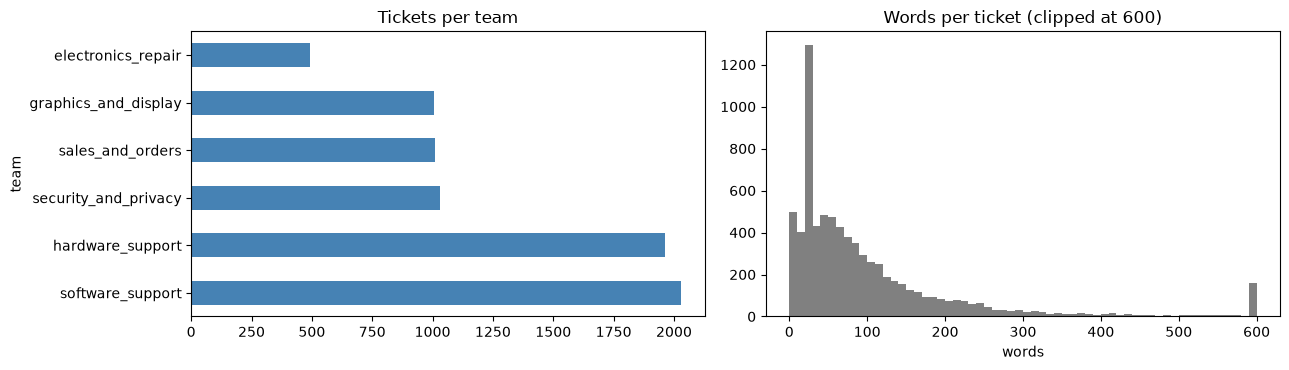

In [4]:
lengths = (raw_tickets["subject"] + " " + raw_tickets["body"]).str.split().str.len()
print("Words per ticket (percentiles 1/25/50/75/99):", np.percentile(lengths, [1, 25, 50, 75, 99]).astype(int))
print(f"Tickets with < {CFG.min_words} words: {(lengths < CFG.min_words).sum()}")
print(f"Tickets with > 1000 words           : {(lengths > 1000).sum()}")

email_like = raw_tickets["body"].str.contains(r"[\w.+-]+@[\w-]+\.[\w.]+", regex=True)
print(f"Tickets containing an e-mail address: {email_like.mean():.1%}")
print(f"Tickets containing HTML tags        : {raw_tickets['body'].str.contains('<br>|<p>').mean():.1%}")
print(f"Exact duplicate bodies              : {raw_tickets['body'].duplicated().sum()}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
raw_tickets["team"].value_counts().plot.barh(ax=axes[0], color="steelblue", title="Tickets per team")
axes[1].hist(np.clip(lengths, 0, 600), bins=60, color="grey")
axes[1].set_title("Words per ticket (clipped at 600)"); axes[1].set_xlabel("words")
plt.tight_layout(); plt.show()

**What we learned:** text lengths range from empty to over a thousand words, about 40% of tickets contain an e-mail address, a third contain HTML, and some bodies appear twice. Careful: a naive `duplicated()` on the raw body is misleading in both directions. It counts the many empty or one-word bodies as "duplicates", and it **misses** the customers who resubmitted the same ticket in different casing and spacing. We need a smarter fingerprint (Section 5).

---
## 4. Clean the text and mask personal data (PII)

**PII = Personally Identifiable Information** (e-mails, phone numbers, card numbers, names, addresses).
Why mask it **before** training?
- **Law and trust:** GDPR / CCPA and PCI-DSS (for card numbers) restrict where personal data may go. Training data, logs and model files are copied to many places.
- **Better models:** an e-mail address is unique noise. Replacing it with a placeholder like `<EMAIL>` keeps the useful signal ("the customer left contact details") and removes the noise.

We use **regular expressions**. Large companies use dedicated tools such as **Microsoft Presidio** (regex + NER models for names and addresses), but the idea is the same. Order matters: card numbers are masked before phone numbers, because a card number contains digit runs that look like phone numbers.

In [5]:
PII_PATTERNS = [                                         # (placeholder, pattern), applied in this order
    ("<EMAIL>", re.compile(r"\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b")),
    ("<URL>", re.compile(r"\bhttps?://\S+|\bwww\.\S+", re.IGNORECASE)),
    ("<CARD>", re.compile(r"\b(?:\d[ -]?){13,16}\b")),            # 13-16 digits, maybe with spaces
    ("<PHONE>", re.compile(r"(?:\+\d{1,2}[ .-]?)?\(?\b\d{3}\)?[ .-]?\d{3}[ .-]\d{4}\b")),
    ("<ORDER_ID>", re.compile(r"\bVC-\d{6}\b", re.IGNORECASE)),
]
HTML_TAG = re.compile(r"<\s*/?\s*(?:p|br|div|span|b|i)\s*/?\s*>", re.IGNORECASE)   # only real HTML tags


def mask_pii(text: str) -> tuple[str, int]:
    """Replace personal data with placeholders. Returns (masked_text, number_of_replacements)."""
    total = 0
    for placeholder, pattern in PII_PATTERNS:
        text, n = pattern.subn(placeholder, text)       # subn = substitute AND count
        total += n
    return text, total


def clean_ticket_text(subject: str, body: str) -> tuple[str, int]:
    """The ONE cleaning function used in training AND in serving (identical behaviour is essential)."""
    text = f"{subject or ''}\n{body or ''}"
    text = HTML_TAG.sub(" ", text)                       # remove <p>, <br> ... (keep our <EMAIL> tags safe)
    text = html.unescape(text)                           # &amp; -> &
    text = re.sub(r"^\s*(re|fwd?)\s*:\s*", "", text, flags=re.IGNORECASE)   # drop "Re:" / "Fwd:"
    text, n_pii = mask_pii(text)
    text = re.sub(r"\s+", " ", text).strip()             # collapse whitespace and newlines
    return text[: CFG.max_chars], n_pii                  # cap very long tickets (code dumps, logs)


example = ("Re: Disk problem", "<p>My SCSI disk is dead &amp; makes noise.<br>Mail me at "
           "john.smith7@gmail.com or call (555) 123-4567. Card 4111 1111 1111 1111, order VC-123456.</p>")
print(clean_ticket_text(*example))

('Disk problem My SCSI disk is dead & makes noise. Mail me at <EMAIL> or call <PHONE>. Card <CARD>, order <ORDER_ID>.', 4)


In [6]:
cleaned = [clean_ticket_text(s, b) for s, b in zip(raw_tickets["subject"], raw_tickets["body"])]
tickets = raw_tickets.assign(text=[t for t, _ in cleaned], n_pii=[n for _, n in cleaned])

print(f"PII items masked: {tickets['n_pii'].sum():,} in {(tickets['n_pii'] > 0).mean():.1%} of tickets")
for placeholder, _ in PII_PATTERNS:
    print(f"  {placeholder:11s} {tickets['text'].str.count(re.escape(placeholder)).sum():6,d}")
# Safety check: no raw e-mail address may survive cleaning
assert not tickets["text"].str.contains(r"[\w.+-]+@[\w-]+\.[a-z]{2,}", regex=True).any()
print("\nNo raw e-mail address left in the cleaned text.")

PII items masked: 8,710 in 55.8% of tickets
  <EMAIL>      3,876
  <URL>            0
  <CARD>         157
  <PHONE>      1,956
  <ORDER_ID>     798



No raw e-mail address left in the cleaned text.


Notice that `<EMAIL>` appears in tickets from **all** teams: the original 1993 posts already contained real e-mail addresses (old e-mail signatures), not just our fake ones. That is exactly what happens with real ticket exports: you always find more PII than you expected. (`<URL>` finds nothing here simply because these 1993 posts predate the web; keep the rule anyway, modern tickets are full of links.)

> **Limits of regex:** regexes do not find names ("Thanks, Maria") or street addresses. For that, Presidio or a NER model (see `04_named_entity_recognition.ipynb`) is used in addition.

---
## 5. Remove duplicates and junk, then split honestly

### Why de-duplicate **before** splitting?
If the same ticket is in the training set *and* in the test set, the model has literally seen the answer. The test score becomes too optimistic (**data leakage**). We build a **fingerprint** of the normalised text (lowercase, letters and digits only) and keep one copy.

### Why remove junk?
"help!!" contains no information about the team. Such tickets are **not** used for training; in production they go straight to a human (see Section 14).

In [7]:
def fingerprint(text: str) -> str:
    """Same fingerprint for texts that differ only in casing, spacing or punctuation."""
    normalised = re.sub(r"[^a-z0-9]+", " ", text.lower()).strip()
    return hashlib.md5(normalised.encode()).hexdigest()


tickets["fingerprint"] = tickets["text"].map(fingerprint)
tickets["n_words"] = tickets["text"].str.split().str.len()

n_before = len(tickets)
dataset = tickets.drop_duplicates("fingerprint", keep="first")             # keep the first copy
n_dupes = n_before - len(dataset)
dataset = dataset[dataset["n_words"] >= CFG.min_words].reset_index(drop=True)
log.info("Removed %d duplicates and %d junk tickets -> %d tickets left",
         n_dupes, n_before - n_dupes - len(dataset), len(dataset))

2026-10-21 17:51:37,912 | INFO | Removed 301 duplicates and 50 junk tickets -> 7179 tickets left


### The split: train / validation / test (stratified)
- **Train (70%)**: the models learn from it.
- **Validation (15%)**: to compare models and to choose the confidence threshold.
- **Test (15%)**: used **once**, at the very end.

`stratify` keeps the team proportions equal in all three parts, which matters for the small `electronics_repair` team.

> **Industry note:** tickets have creation dates. With real data you would usually prefer a **time-based split** (train on January to August, test on September) because products and topics change over time. Our stand-in data has no reliable dates, so we use a stratified random split.

In [8]:
train_df, temp_df = train_test_split(dataset, test_size=CFG.val_size + CFG.test_size,
                                     stratify=dataset["team"], random_state=CFG.random_state)
val_df, test_df = train_test_split(temp_df, test_size=CFG.test_size / (CFG.val_size + CFG.test_size),
                                   stratify=temp_df["team"], random_state=CFG.random_state)
for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s}: {len(part):5,d} tickets | " +
          " ".join(f"{t[:8]}={s:.0%}" for t, s in part["team"].value_counts(normalize=True).sort_index().items()))
assert not set(train_df["fingerprint"]) & set(test_df["fingerprint"]), "duplicate leaked into test!"

train: 5,025 tickets | electron=6% graphics=13% hardware=26% sales_an=13% security=14% software=27%
val  : 1,077 tickets | electron=6% graphics=13% hardware=26% sales_an=13% security=14% software=27%
test : 1,077 tickets | electron=6% graphics=13% hardware=26% sales_an=13% security=14% software=27%


---
## 6. Baselines: dummy and TF-IDF + linear model

**Always start simple.**
1. **Dummy model**: always predicts the biggest team. Any real model must beat it by a lot.
2. **TF-IDF + Logistic Regression**: the **workhorse of production text classification**. It trains in about a minute or less on a CPU, routes a ticket in milliseconds, needs no GPU, and is easy to explain. Many companies never need anything else.

**TF-IDF** turns a text into a long vector with one number per word (or word pair): high when the word is frequent in *this* ticket but rare in *other* tickets. Useful options:
- `ngram_range=(1, 2)`: also use word pairs such as "hard drive" or "for sale".
- `sublinear_tf=True`: a word that appears 20 times is not 20× more important than one that appears once.
- `min_df=2`: ignore words that appear in only one ticket (typos, IDs).

We measure **accuracy** and **macro-F1** (the average F1 over teams, so the small teams count as much as the big ones).

In [9]:
X_train, y_train = train_df["text"], train_df["team"]
X_val, y_val = val_df["text"], val_df["team"]
X_test, y_test = test_df["text"], test_df["team"]


def evaluate(name: str, y_true, y_pred) -> dict:
    return {"model": name, "accuracy": round(accuracy_score(y_true, y_pred), 3),
            "macro_f1": round(f1_score(y_true, y_pred, average="macro"), 3)}


dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
results = [evaluate("Dummy (biggest team)", y_val, dummy.predict(X_val))]

tfidf_template = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2, max_df=0.9,
                              strip_accents="unicode", max_features=200_000)),
    ("clf", LogisticRegression(max_iter=2000)),
])

# Tune the single most important knob, the regularisation strength C, on the validation set
for C in [1.0, 5.0, 20.0]:
    candidate = clone(tfidf_template).set_params(clf__C=C)     # clone = fresh, unfitted copy
    start = time.perf_counter()
    candidate.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start
    results.append(evaluate(f"TF-IDF + LogReg (C={C:g})", y_val, candidate.predict(X_val))
                   | {"train_seconds": round(fit_seconds, 1)})

pd.DataFrame(results)

,model,accuracy,macro_f1,train_seconds
0,Dummy (biggest team),0.267,0.070,NaN
1,TF-IDF + LogReg (C=1),0.776,0.702,24.8
2,TF-IDF + LogReg (C=5),0.809,0.777,28.4
3,TF-IDF + LogReg (C=20),0.817,0.796,36.1


In [10]:
best_C = max((r for r in results if "C=" in r["model"]), key=lambda r: r["macro_f1"])["model"]
best_C = float(re.search(r"C=([\d.]+)", best_C).group(1))
tfidf_model = clone(tfidf_template).set_params(clf__C=best_C).fit(X_train, y_train)
print(f"Chosen C = {best_C:g} | vocabulary size: {len(tfidf_model['tfidf'].vocabulary_):,} terms")

Chosen C = 20 | vocabulary size: 65,822 terms


---
## 7. A transformer: sentence embeddings + logistic regression

A **sentence embedding model** turns each ticket into a dense vector of 384 numbers that captures its *meaning*, so "my screen stays black" and "monitor shows nothing" end up close together even without shared words (see `09_sentence_embeddings_advanced.ipynb`).

The cheapest way to use a transformer in industry is:
1. **Freeze** a pretrained embedding model (no fine-tuning, no GPU).
2. Train a small **logistic regression** on top of the embeddings.

We use `all-MiniLM-L6-v2` (~90 MB, 6 layers). It can read up to **256 word pieces**; anything after that is silently ignored. We cut it further to **128 word pieces** (roughly the first 90 words): the first lines of a ticket usually say what it is about, and transformer cost grows quickly with input length. This kind of speed/quality trade-off is a normal engineering decision.

> If you see a warning about `HF_TOKEN` when the model loads, you can ignore it: a Hugging Face token only raises download rate limits.

> Fine-tuning a full BERT model (see `03_text_classification.ipynb`) or SetFit usually scores higher, but needs more compute and engineering. Frozen embeddings are a common first step.

In [11]:
from sentence_transformers import SentenceTransformer

encoder = SentenceTransformer(CFG.embedding_model, device="cpu")   # downloads ~90 MB once, then cached
encoder.max_seq_length = 128          # read only the first 128 word pieces (faster; see text above)
log.info("Embedding model loaded: dim=%d, max_seq_length=%d",
         encoder.get_sentence_embedding_dimension(), encoder.max_seq_length)


def embed(texts, batch_size: int = 64) -> np.ndarray:
    """Texts -> L2-normalised embedding matrix (one row per text)."""
    return encoder.encode(list(texts), batch_size=batch_size, normalize_embeddings=True,
                          show_progress_bar=False, convert_to_numpy=True)


start = time.perf_counter()
E_train, E_val, E_test = embed(X_train), embed(X_val), embed(X_test)
embed_seconds = time.perf_counter() - start
n_embedded = len(X_train) + len(X_val) + len(X_test)
print(f"Embedded {n_embedded:,} tickets in {embed_seconds:.0f}s "
      f"({1000 * embed_seconds / n_embedded:.1f} ms per ticket on CPU) | matrix shape {E_train.shape}")

2026-10-21 17:53:58,738 | WARNING | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.


2026-10-21 17:54:04,360 | INFO | Embedding model loaded: dim=384, max_seq_length=128


Embedded 7,179 tickets in 258s (35.9 ms per ticket on CPU) | matrix shape (5025, 384)


In [12]:
emb_results = []
for C in [1.0, 10.0, 50.0]:
    candidate = LogisticRegression(C=C, max_iter=3000).fit(E_train, y_train)
    emb_results.append(evaluate(f"MiniLM embeddings + LogReg (C={C:g})", y_val, candidate.predict(E_val)) | {"C": C})
emb_best = max(emb_results, key=lambda r: r["macro_f1"])
emb_clf = LogisticRegression(C=emb_best["C"], max_iter=3000).fit(E_train, y_train)
results += [{k: v for k, v in r.items() if k != "C"} for r in emb_results]

# A cheap "ensemble": average the probabilities of both models (same team order: classes_ are sorted)
assert list(tfidf_model.classes_) == list(emb_clf.classes_)
proba_val_tfidf = tfidf_model.predict_proba(X_val)
proba_val_emb = emb_clf.predict_proba(E_val)
proba_val_ens = (proba_val_tfidf + proba_val_emb) / 2
results.append(evaluate("Ensemble (TF-IDF + MiniLM, averaged)", y_val,
                        tfidf_model.classes_[proba_val_ens.argmax(axis=1)]))
pd.DataFrame(results).drop(columns="train_seconds")

,model,accuracy,macro_f1
0,Dummy (biggest team),0.267,0.070
1,TF-IDF + LogReg (C=1),0.776,0.702
2,TF-IDF + LogReg (C=5),0.809,0.777
3,TF-IDF + LogReg (C=20),0.817,0.796
4,MiniLM embeddings + LogReg (C=1),0.776,0.752
5,MiniLM embeddings + LogReg (C=10),0.783,0.767
6,MiniLM embeddings + LogReg (C=50),0.764,0.741
7,"Ensemble (TF-IDF + MiniLM, averaged)",0.836,0.818


**Reading the table honestly:**
- **TF-IDF + LogReg** (C = 20) reaches about **0.82 accuracy / 0.80 macro-F1** on validation.
- The **frozen MiniLM embeddings lose** (about 0.78 / 0.77, best C = 10). This surprises many beginners, but it is common: a general-purpose embedding squeezes a whole ticket into 384 numbers and blurs the specific technical words (`SCSI`, `Motif`, `PGP`, `for sale`) that TF-IDF keeps as separate features. With thousands of labelled tickets, TF-IDF + a linear model is very hard to beat. Transformers shine when labelled data is scarce, or when they are **fine-tuned** on your data (not done here).
- The **ensemble** is the best (about **0.84 / 0.82**): the two models make *different* mistakes, so averaging them helps. Whether ~2 points are worth running a transformer in production is a business question: next section.

---
## 8. Compare quality, speed and cost

Accuracy is only one column of the decision. Engineers and managers also ask:
- **Latency:** how long does one ticket take? (Matters for live chat.)
- **Throughput & cost:** how much hardware do 40,000 tickets per month need?
- **Size & dependencies:** a ~6 MB scikit-learn file vs. a ~90 MB model plus PyTorch (≈1 GB installed).

In [13]:
def single_ticket_latency_ms(predict_one, texts, n: int = 200) -> float:
    """Median time to route ONE ticket (the live-chat scenario), in milliseconds."""
    timings = []
    for text in texts[:n]:
        start = time.perf_counter()
        predict_one(text)
        timings.append((time.perf_counter() - start) * 1000)
    return float(np.median(timings))


sample_texts = list(X_val)
print(f"CPU load average while measuring: {os.getloadavg()[0]:.1f} (this machine has {os.cpu_count()} cores)")
lat_tfidf = single_ticket_latency_ms(lambda t: tfidf_model.predict_proba([t]), sample_texts)
lat_emb = single_ticket_latency_ms(lambda t: emb_clf.predict_proba(embed([t])), sample_texts, n=50)

with tempfile.TemporaryDirectory() as tmp:                          # measure the size on disk
    joblib.dump(tfidf_model, Path(tmp) / "m.joblib")
    tfidf_mb = (Path(tmp) / "m.joblib").stat().st_size / 1e6
emb_mb = sum(p.numel() * p.element_size() for p in encoder.parameters()) / 1e6   # weights in memory

# 1 CPU core costs roughly $0.04 per hour in the cloud (assumption for illustration)
def monthly_compute_usd(ms_per_ticket: float) -> float:
    return CFG.monthly_tickets * ms_per_ticket / 1000 / 3600 * 0.04

comparison = pd.DataFrame([
    {"model": "TF-IDF + LogReg", **evaluate("", y_val, tfidf_model.predict(X_val)),
     "ms_per_ticket": round(lat_tfidf, 2), "model_size_mb": round(tfidf_mb, 1)},
    {"model": "MiniLM + LogReg", **evaluate("", y_val, emb_clf.predict(E_val)),
     "ms_per_ticket": round(lat_emb, 2), "model_size_mb": round(emb_mb, 1)},
]).drop(columns="model").set_index(pd.Index(["TF-IDF + LogReg", "MiniLM + LogReg"], name="model"))
comparison["compute_usd_per_month"] = comparison["ms_per_ticket"].map(monthly_compute_usd).round(4)
comparison

CPU load average while measuring: 16.5 (this machine has 8 cores)


,accuracy,macro_f1,ms_per_ticket,model_size_mb,compute_usd_per_month
model,,,,,
TF-IDF + LogReg,0.817,0.796,3.79,5.8,0.0017
MiniLM + LogReg,0.783,0.767,153.10,90.9,0.0680


**What this means in practice:**
- TF-IDF answers in a few milliseconds; MiniLM is roughly **40× slower** per ticket on a CPU here. These timings were measured on a shared machine that was busy with other jobs (see the load printed above), so the absolute numbers are pessimistic and will differ on your computer; the **ratio** is what matters. On a GPU, or with batching, the transformer gets much faster but also more expensive to host.
- Even so, raw compute is **cheap at this volume** (well under \$1 per month for both). The real costs of the transformer are operational: ~90 MB of weights plus PyTorch (≈1 GB installed), more RAM, slower start-up, bigger Docker images and one more model to update.
- So the decision depends on the quality gain, which we translate into dollars in Section 10.

---
## 9. Error analysis: where does the model fail?

A single accuracy number hides **which** teams suffer. The **per-class report** and the **confusion matrix** show it. Rows = true team, columns = predicted team; everything off the diagonal is a misroute.

                      precision    recall  f1-score   support

  electronics_repair      0.854     0.507     0.636        69
graphics_and_display      0.769     0.715     0.741       144
    hardware_support      0.775     0.865     0.817       282
    sales_and_orders      0.930     0.821     0.872       145
security_and_privacy      0.932     0.832     0.879       149
    software_support      0.782     0.885     0.831       288

            accuracy                          0.817      1077
           macro avg      0.840     0.771     0.796      1077
        weighted avg      0.824     0.817     0.815      1077



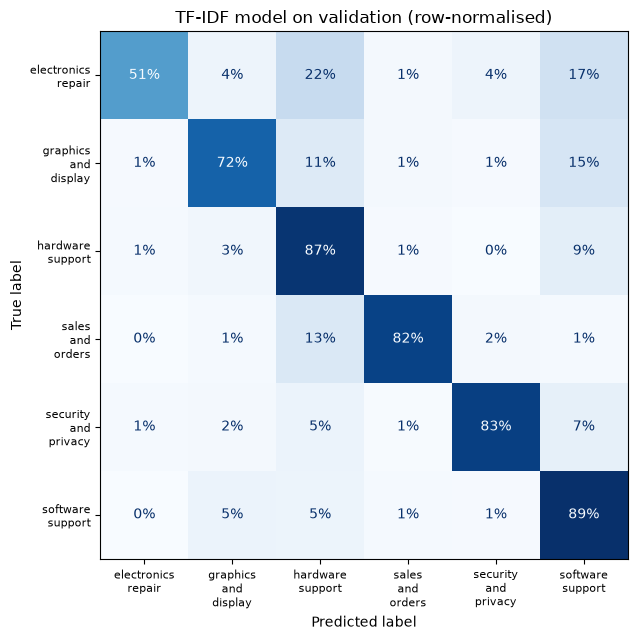

Most frequent misroutes:
team                  col_0           
hardware_support      software_support    25
graphics_and_display  software_support    21
sales_and_orders      hardware_support    19
graphics_and_display  hardware_support    16
electronics_repair    hardware_support    15


In [14]:
val_pred = tfidf_model.predict(X_val)
print(classification_report(y_val, val_pred, digits=3))

fig, ax = plt.subplots(figsize=(7.5, 6.5))
ConfusionMatrixDisplay(confusion_matrix(y_val, val_pred, labels=TEAMS, normalize="true"),
                       display_labels=[t.replace("_", "\n") for t in TEAMS]).plot(
    ax=ax, values_format=".0%", colorbar=False, cmap="Blues")
ax.set_title("TF-IDF model on validation (row-normalised)")
plt.xticks(rotation=0, fontsize=8); plt.yticks(fontsize=8); plt.tight_layout(); plt.show()

# The same information as text: the most frequent misroutes (true team -> predicted team)
confusions = pd.crosstab(y_val, val_pred).stack()
confusions = confusions[[a != b for a, b in confusions.index]].sort_values(ascending=False)
print("Most frequent misroutes:\n" + confusions.head(5).to_string())

In [15]:
# Read actual mistakes: the most confident WRONG predictions are the most instructive
val_view = val_df.assign(pred=val_pred, confidence=tfidf_model.predict_proba(X_val).max(axis=1))
worst = val_view[val_view["pred"] != val_view["team"]].sort_values("confidence", ascending=False)
pd.set_option("display.max_colwidth", 110)
worst[["team", "team_gold", "pred", "confidence", "text"]].head(8)

,team,team_gold,pred,confidence,text
5817,sales_and_orders,security_and_privacy,security_and_privacy,0.997458,"Secret algorithm [Re: Clipper Chip and crypto key-escrow] I take it you mean President Nixon, not private ..."
1690,security_and_privacy,sales_and_orders,sales_and_orders,0.994584,"FOR SALE: ULTRABOTS PC GAME Electronics Art's Ultrabots game for sale with book and original 3.5"" disks in..."
1387,graphics_and_display,hardware_support,hardware_support,0.993574,IDE vs SCSI I have been following this thread and figured I'd throw in my two cents... The Amiga Zorro II ...
2739,hardware_support,hardware_support,software_support,0.979571,Application Errors on WIN31 H E L P ! I have a problem in which I'm getting increasing frustrated every da...
6040,electronics_repair,security_and_privacy,security_and_privacy,0.968409,How to make the Clipper chip and wiretapping less bad I've got an idea that would remove most of the polit...
660,sales_and_orders,security_and_privacy,security_and_privacy,0.960866,text of White House announcement and Q&As on clipper chip encryption The dead giveaway is the repeated pro...
396,security_and_privacy,software_support,software_support,0.960790,"Windows for WorkGroups and LAN Workplace Hey, sounds great. Does that mean that W4WG works with ODI? I tho..."
3091,graphics_and_display,graphics_and_display,sales_and_orders,0.960418,GIANT SOFTWARE YARDSALE SOFTWARE RETAIL / SALE Price //////GRAPHICS///////// COREL DRAW 2.0 300 / 25 ALDUS...


**What the error analysis tells us:**
- `electronics_repair`, the smallest team (6% of tickets), has by far the lowest **recall** (~51%): half of its tickets are sent elsewhere, most often to `hardware_support` (see the list of most frequent misroutes). Small classes are always the first victims; fixes are more labelled examples for that team, class weights, or a lower threshold for that class.
- The two big merged queues (`hardware_support`, `software_support`) have high recall (~87-89%) but lower precision (~78%): all five most frequent misroutes end in one of them. They act as "catch-alls" for ambiguous computer questions.
- Look at the **most confident "mistakes"**: in 6 of the 8 rows the true label (`team_gold`) **equals the model's prediction**. The model was right and the *agent's tag* was wrong! Sorting disagreements by confidence is a cheap, very effective way to find label errors (the idea behind tools like `cleanlab`): send those tickets to a reviewer, fix the labels, retrain.

---
## 10. Confidence threshold: auto-route or send to a human

The model outputs a probability for every team. The highest one is its **confidence**. Policy:
- confidence ≥ threshold → **auto-route** to the predicted team;
- otherwise → **human triage** queue (\$2).

A higher threshold = fewer automatic routes but fewer costly mistakes (\$8 each). We pick the threshold that **minimises total cost on the validation set**, and we also show the coverage / accuracy trade-off.

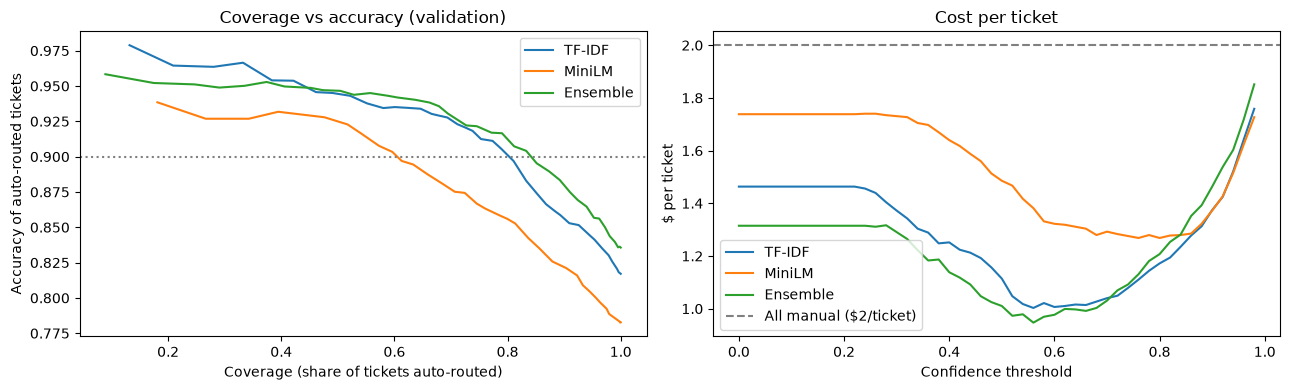

,threshold,coverage,auto_accuracy,cost_usd,cost_per_ticket
TF-IDF,0.56,0.773,0.911,1080.0,1.003
MiniLM,0.76,0.633,0.894,1366.0,1.268
Ensemble,0.56,0.790,0.917,1020.0,0.947


In [16]:
def routing_cost(y_true, proba, classes, threshold: float) -> dict:
    """Simulate the auto-route / human-triage policy and return its business numbers."""
    y_true = np.asarray(y_true)
    confidence = proba.max(axis=1)
    predicted = classes[proba.argmax(axis=1)]
    auto = confidence >= threshold
    wrong_auto = auto & (predicted != y_true)
    cost = (~auto).sum() * CFG.cost_manual_triage + wrong_auto.sum() * CFG.cost_misroute
    return {"threshold": threshold, "coverage": auto.mean(),
            "auto_accuracy": 1 - wrong_auto.sum() / max(auto.sum(), 1),
            "cost_usd": cost, "cost_per_ticket": cost / len(y_true)}


thresholds = np.round(np.arange(0.0, 1.0, 0.02), 2)
curves = {name: pd.DataFrame([routing_cost(y_val, p, tfidf_model.classes_, t) for t in thresholds])
          for name, p in [("TF-IDF", proba_val_tfidf), ("MiniLM", proba_val_emb), ("Ensemble", proba_val_ens)]}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, curve in curves.items():
    axes[0].plot(curve["coverage"], curve["auto_accuracy"], label=name)
    axes[1].plot(curve["threshold"], curve["cost_per_ticket"], label=name)
axes[0].set_xlabel("Coverage (share of tickets auto-routed)"); axes[0].set_ylabel("Accuracy of auto-routed tickets")
axes[0].axhline(0.9, color="grey", ls=":"); axes[0].set_title("Coverage vs accuracy (validation)")
axes[1].axhline(CFG.cost_manual_triage, color="grey", ls="--", label="All manual ($2/ticket)")
axes[1].set_xlabel("Confidence threshold"); axes[1].set_ylabel("$ per ticket"); axes[1].set_title("Cost per ticket")
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

best_rows = {name: c.loc[c["cost_usd"].idxmin()] for name, c in curves.items()}
pd.DataFrame(best_rows).T.round(3)

**The decision:**
- **TF-IDF** at threshold ≈ 0.56 auto-routes ≈ 77% of validation tickets with ≈ 91% accuracy, for ≈ \$1.00 per ticket instead of \$2.00 when humans triage everything. It meets our "≈ 90% auto-routed accuracy" goal.
- **MiniLM alone** is the worst option (≈ \$1.27 per ticket): it is less accurate, so it must send more tickets to humans.
- The **ensemble** is the cheapest (≈ \$0.95 per ticket, ≈ 79% coverage). At 40,000 tickets per month that is roughly \$2,200 per month more saving than TF-IDF alone, which would probably pay for the extra infrastructure.
- **Our plan:** ship the simple TF-IDF router as **v1** now (fast, small, easy to explain and debug), and treat the ensemble as the **v2 candidate** to be confirmed with an A/B test on live traffic. "Simple first, then prove the complex model is worth it" is the standard industry path.

In [17]:
# The production choice (see the text above): the TF-IDF model and its cost-optimal threshold
THRESHOLD = float(best_rows["TF-IDF"]["threshold"])
log.info("Chosen model: TF-IDF + LogReg | threshold = %.2f", THRESHOLD)

2026-10-21 17:59:59,314 | INFO | Chosen model: TF-IDF + LogReg | threshold = 0.56


---
## 11. Final test-set evaluation

Now we open the locked drawer **once**. We report the plain classifier metrics **and** the business numbers of the routing policy, then compare against the measured-vs-true label problem.

In [18]:
proba_test = tfidf_model.predict_proba(X_test)
test_pred = tfidf_model.classes_[proba_test.argmax(axis=1)]
policy = routing_cost(y_test, proba_test, tfidf_model.classes_, THRESHOLD)
all_manual_cost = len(y_test) * CFG.cost_manual_triage

test_metrics = {
    "accuracy_all_tickets": round(accuracy_score(y_test, test_pred), 3),
    "macro_f1_all_tickets": round(f1_score(y_test, test_pred, average="macro"), 3),
    "threshold": THRESHOLD,
    "coverage_auto_routed": round(policy["coverage"], 3),
    "accuracy_auto_routed": round(policy["auto_accuracy"], 3),
    "cost_per_ticket_usd": round(policy["cost_per_ticket"], 3),
    "cost_per_ticket_all_manual_usd": CFG.cost_manual_triage,
}
print(json.dumps(test_metrics, indent=2))
saving = (all_manual_cost - policy["cost_usd"]) / len(y_test) * CFG.monthly_tickets
print(f"\nEstimated saving: ${saving:,.0f} per month at {CFG.monthly_tickets:,} tickets "
      f"(and {policy['coverage']:.0%} of tickets get routed instantly instead of waiting for a human)")

# The MiniLM model on the same test set, for the record (we do NOT use this to change our decision)
print(f"\nFor reference, MiniLM + LogReg on test: accuracy {accuracy_score(y_test, emb_clf.predict(E_test)):.3f}, "
      f"macro-F1 {f1_score(y_test, emb_clf.predict(E_test), average='macro'):.3f}")

{
  "accuracy_all_tickets": 0.823,
  "macro_f1_all_tickets": 0.806,
  "threshold": 0.56,
  "coverage_auto_routed": 0.763,
  "accuracy_auto_routed": 0.909,
  "cost_per_ticket_usd": 1.031,
  "cost_per_ticket_all_manual_usd": 2.0
}

Estimated saving: $38,774 per month at 40,000 tickets (and 76% of tickets get routed instantly instead of waiting for a human)

For reference, MiniLM + LogReg on test: accuracy 0.776, macro-F1 0.762


In [19]:
# Label noise audit: what if a senior agent re-checked every test label?
acc_noisy = accuracy_score(test_df["team"], test_pred)
acc_gold = accuracy_score(test_df["team_gold"], test_pred)
print(f"Accuracy against agent labels (noisy): {acc_noisy:.3f}")
print(f"Accuracy against true labels (gold)  : {acc_gold:.3f}")
print(f"Test labels that are wrong            : {(test_df['team'] != test_df['team_gold']).mean():.1%}")

Accuracy against agent labels (noisy): 0.823
Accuracy against true labels (gold)  : 0.843
Test labels that are wrong            : 2.7%


**Reading the final numbers:**
- On the untouched test set the classifier reaches **82.3% accuracy / 0.806 macro-F1**, very close to validation (81.7% / 0.796), so we did not over-fit our choices to the validation set.
- The routing policy auto-routes **76%** of tickets with **90.9%** accuracy and costs **\$1.03 per ticket instead of \$2.00**, roughly **\$39k saved per month** at 40,000 tickets (under the cost assumptions in the config). The remaining 24% still reach a human, as designed.
- **Label noise lowers the measured score:** 2.7% of the test labels are wrong, and against the true labels accuracy is **84.3%** instead of 82.3%. For important decisions, companies have a small "gold" test set re-labelled carefully by experts.

---
## 12. Explain predictions with top TF-IDF terms

Agents will ask "**why** did this ticket go to security?". With a linear model the answer is simple and exact:

score(team) = Σ (TF-IDF weight of word × coefficient of word for that team)

So the words with the largest **weight × coefficient** are the reasons. First, the global view: the strongest words per team.

In [20]:
vocab = np.array(tfidf_model["tfidf"].get_feature_names_out())
coefs = tfidf_model["clf"].coef_                       # shape: (n_teams, n_terms)
top_terms = {team: vocab[np.argsort(coefs[i])[::-1][:10]] for i, team in enumerate(tfidf_model.classes_)}
pd.DataFrame(top_terms)

,electronics_repair,graphics_and_display,hardware_support,sales_and_orders,security_and_privacy,software_support
0,circuit,graphics,mac,sale,clipper,windows
1,electronics,3d,monitor,for sale,encryption,window
2,scope,image,apple,forsale,key,motif
3,motorola,tiff,monitors,sell,government,win
4,the disks,pov,scsi,offer,crypto,microsoft
5,disks copy,images,simms,condition,des,x11r5
6,copy protected,3do,ide,shipping,pgp,server
7,frequency,viewer,cpu,00,escrow,widget
8,audio,cview,drive,asking,wiretap,nt
9,ir,gif,card,new,cryptography,for windows


In [21]:
def explain_ticket(text: str, top_n: int = 5) -> list[tuple[str, float]]:
    """Words that pushed this ticket towards its predicted team (weight x coefficient)."""
    x = tfidf_model["tfidf"].transform([text])                         # sparse row vector
    team_idx = int(tfidf_model.predict_proba([text]).argmax())
    contributions = x.multiply(coefs[team_idx]).tocsr()                 # element-wise product
    order = np.argsort(contributions.data)[::-1][:top_n]
    return [(vocab[contributions.indices[i]], round(float(contributions.data[i]), 3)) for i in order]


for text in X_test.iloc[:3]:
    team = tfidf_model.predict([text])[0]
    print(f"[{team}] {text[:100]}...\n   because of: {explain_ticket(text)}\n")

[graphics_and_display] Wanted: 3d rendering lib for PC Does any one know of a decent quality library of routines for perfor...
   because of: [('3d', 1.141), ('graphics', 0.705), ('surface', 0.372), ('ray', 0.325), ('map', 0.28)]

[software_support] ATM -----Or, if you need to use a service bureau and they're only set up to use Type 1 fonts. From w...
   because of: [('fonts', 0.562), ('to use', 0.207), ('set', 0.183), ('tt', 0.166), ('type', 0.152)]

[electronics_repair] help - how to construct home-built battery for 3rd grade sci report Thanks, Yuki <EMAIL>...
   because of: [('battery', 0.497), ('how', 0.149), ('help', 0.137), ('to construct', 0.135), ('built battery', 0.135)]



These explanations double as a **sanity check**: if the top words were `<EMAIL>`, `subject` or a customer name, the model would be learning shortcuts instead of content.

**We actually found one!** Look at the `electronics_repair` column above: `the disks`, `disks copy`, `copy protected`. That is not electronics vocabulary. It comes from one long discussion thread whose subject line, *"How to the disks copy protected."*, is repeated in dozens of replies. The model memorised the **thread subject**. In a ticket system the same happens with e-mail threads ("Re: Re: Order 12345"). Two lessons:
1. Read the top features of every class before shipping.
2. Messages from the **same conversation** should stay in the **same split** (e.g. `GroupShuffleSplit` with a conversation id), otherwise the test score is inflated by near-duplicates. (For transformer models you would need tools like SHAP or attention attribution; see `03_Machine_Learning/07_explainability/`.)

---
## 13. Save the pipeline and its metadata

We save the whole scikit-learn **pipeline** (TF-IDF + classifier) and a **metadata** file with everything an engineer needs six months from now: threshold, team list, library versions, test metrics and the training label distribution (used by monitoring in Section 15).

We save into a temporary folder. In a real project this would be `models/ticket_router/v1/`, and the cleaning function would live in an importable Python package (e.g. `ticket_router/cleaning.py`) so that training and serving share **exactly** the same code.

In [22]:
ARTIFACT_DIR = Path(tempfile.mkdtemp(prefix="ticket_router_"))     # real life: models/ticket_router/v1/
joblib.dump(tfidf_model, ARTIFACT_DIR / "pipeline.joblib")

train_distribution = y_train.value_counts(normalize=True).sort_index()
metadata = {
    "model_name": "ticket_router",
    "model_version": "1.0.0",
    "algorithm": f"TF-IDF(1-2 grams) + LogisticRegression(C={best_C:g})",
    "trained_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "sklearn_version": sklearn.__version__,
    "teams": list(tfidf_model.classes_),
    "confidence_threshold": THRESHOLD,
    "min_words": CFG.min_words,
    "max_chars": CFG.max_chars,
    "n_training_tickets": int(len(train_df)),
    "train_label_distribution": train_distribution.round(4).to_dict(),
    "val_mean_confidence": round(float(proba_val_tfidf.max(axis=1).mean()), 4),
    "test_metrics": test_metrics,
    "config": asdict(CFG),
}
(ARTIFACT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))
for f in sorted(ARTIFACT_DIR.iterdir()):
    print(f"{f.name:16s} {f.stat().st_size / 1e6:6.2f} MB")

metadata.json      0.00 MB
pipeline.joblib    5.77 MB


---
## 14. Serve the model: a routing function with input validation

In production, the ticket system calls our model through an API (see `12_FastAPI/03_ml_serving_with_fastapi.ipynb`). The serving code must:
1. **Validate** the request with **Pydantic** (types, lengths, allowed channels).
2. Apply the **same** cleaning and PII masking as in training.
3. Handle edge cases on purpose: too short → human; low confidence → human.
4. Return a decision **plus the reason**, the model version and the latency (for logs and dashboards).

In [23]:
from typing import Literal
from pydantic import BaseModel, Field, ValidationError


class TicketRequest(BaseModel):
    """The shape of a routing request. Pydantic rejects anything else with a clear message."""
    ticket_id: str = Field(min_length=1, max_length=64)
    channel: Literal["email", "web", "chat"]
    subject: str = Field(default="", max_length=500)
    body: str = Field(max_length=50_000)                # bigger payloads are rejected, not processed


class TicketRouter:
    """Loads the pipeline once at start-up and routes tickets."""

    def __init__(self, artifact_dir: Path):
        self.pipeline = joblib.load(artifact_dir / "pipeline.joblib")
        self.meta = json.loads((artifact_dir / "metadata.json").read_text())
        log.info("Loaded %s v%s", self.meta["model_name"], self.meta["model_version"])

    def route(self, payload: dict) -> dict:
        start = time.perf_counter()
        request = TicketRequest(**payload)                                  # raises ValidationError if bad
        text, n_pii = clean_ticket_text(request.subject, request.body)       # SAME cleaning as training
        response = {"ticket_id": request.ticket_id, "model_version": self.meta["model_version"],
                    "pii_masked": n_pii}
        if len(text.split()) < self.meta["min_words"]:
            response |= {"route_to": "human_triage", "reason": "too_short", "team": None, "confidence": None}
        else:
            proba = self.pipeline.predict_proba([text])[0]
            best = int(proba.argmax())
            confident = proba[best] >= self.meta["confidence_threshold"]
            response |= {"team": self.meta["teams"][best], "confidence": round(float(proba[best]), 3),
                         "route_to": self.meta["teams"][best] if confident else "human_triage",
                         "reason": "confident" if confident else "low_confidence",
                         "top_terms": [w for w, _ in explain_ticket(text, 3)]}
        response["latency_ms"] = round((time.perf_counter() - start) * 1000, 2)
        return response


router = TicketRouter(ARTIFACT_DIR)      # simulates a fresh application start-up
requests = [
    {"ticket_id": "T-1", "channel": "web", "subject": "Hard drive not detected",
     "body": "<p>My new IDE hard drive is not detected by the BIOS after I set the jumpers.<br>"
             "Email: anna.k@gmail.com</p>"},
    {"ticket_id": "T-2", "channel": "email", "subject": "Selling my old monitor",
     "body": "I want to sell my 17 inch monitor, asking $150 plus shipping. Call (555) 201-3344."},
    {"ticket_id": "T-3", "channel": "chat", "body": "help!!"},
    {"ticket_id": "T-4", "channel": "email", "subject": "Question",
     "body": "Hi, I have a question about something, can someone get back to me soon please?"},
]
pd.DataFrame([router.route(r) for r in requests])

2026-10-21 18:00:04,423 | INFO | Loaded ticket_router v1.0.0


,ticket_id,model_version,pii_masked,team,confidence,route_to,reason,top_terms,latency_ms
0,T-1,1.0.0,1,hardware_support,0.856,hardware_support,confident,"[drive, ide, bios]",6.90
1,T-2,1.0.0,1,sales_and_orders,0.913,sales_and_orders,confident,"[sell, shipping, asking]",6.44
2,T-3,1.0.0,0,None,NaN,human_triage,too_short,NaN,0.09
3,T-4,1.0.0,0,hardware_support,0.677,hardware_support,confident,"[someone, question, question hi]",6.83


**Look closely at T-4.** "Hi, I have a question about something..." contains **no information about the team**, yet the model routes it to `hardware_support` with confidence 0.68, above our threshold. Its "reasons" are `someone`, `question`, `question hi`. A classifier **must** pick one of the six teams; its probabilities are not an "I don't know" detector, and with no evidence it leans towards a big, generic class. Common fixes in production:
1. Add an **"unclear / needs more info"** class trained on real vague tickets (with an automatic "please tell us more" reply).
2. A rule on top of the model: require a minimum number of words that the model actually knows (not just `hi`, `question`, `please`).
3. Out-of-distribution detection (Section 15 shows the simplest signals).

In [24]:
# Bad requests must fail loudly with a clear message, never produce a silent wrong answer
bad_requests = [{"ticket_id": "T-5", "channel": "fax", "body": "Printer broken"},
                {"ticket_id": "", "channel": "email", "body": "x" * 60_000}]
for bad in bad_requests:
    try:
        router.route(bad)
    except ValidationError as err:
        print(f"Rejected ({err.error_count()} problems): " +
              "; ".join(f"{e['loc'][0]}: {e['msg']}" for e in err.errors()))

Rejected (1 problems): channel: Input should be 'email', 'web' or 'chat'
Rejected (2 problems): ticket_id: String should have at least 1 character; body: String should have at most 50000 characters


---
## 15. Monitoring: label shift and new, unseen topics

After launch, two things typically go wrong:

1. **Label (prior) shift:** the *mix* of tickets changes, e.g. a Black-Friday sale doubles the `sales_and_orders` share. The model may still be fine, but staffing and thresholds may need updating.
2. **New topics:** VoltCart starts selling **car electronics and space-themed gadgets**. Those tickets belong to no existing team. The model will still pick one of its six teams (it has no other choice!), so we must detect them.

Signals we can compute **without labels** (labels arrive days later, if ever):
- **Predicted team distribution** vs. training distribution, summarised with the **PSI** (Population Stability Index; > 0.1 investigate, > 0.25 act).
- **Share of low-confidence tickets** and **mean confidence**.
- **Out-of-vocabulary rate**: share of words the TF-IDF model has never seen.

In [25]:
def psi(expected: pd.Series, actual: pd.Series, eps: float = 1e-4) -> float:
    """Population Stability Index between two category distributions (shares that sum to 1)."""
    e, a = expected.clip(lower=eps), actual.reindex(expected.index, fill_value=0).clip(lower=eps)
    return float(((a - e) * np.log(a / e)).sum())


analyzer = tfidf_model["tfidf"].build_analyzer()      # the exact tokenizer used by the model
known_terms = tfidf_model["tfidf"].vocabulary_


def monitoring_report(texts: pd.Series, name: str) -> dict:
    proba = router.pipeline.predict_proba(texts)
    predicted = pd.Series(router.pipeline.classes_[proba.argmax(axis=1)])
    words = [w for t in texts for w in analyzer(t) if " " not in w]   # unigrams only
    return {"batch": name, "tickets": len(texts),
            "psi_predicted_teams": round(psi(train_distribution, predicted.value_counts(normalize=True)), 3),
            "low_confidence_share": round(float((proba.max(axis=1) < THRESHOLD).mean()), 3),
            "mean_confidence": round(float(proba.max(axis=1).mean()), 3),
            "oov_rate": round(float(np.mean([w not in known_terms for w in words])), 3)}


# Week A: normal traffic (held-out test tickets)
week_normal = test_df["text"]
# Week B: Black-Friday sale -> sales tickets are 3x more common
sales = test_df[test_df["team"] == "sales_and_orders"]["text"]
week_sale = pd.concat([test_df["text"], sales, sales], ignore_index=True)
# Week C: new product lines -> car and space tickets the model has never seen
new_topics = load_posts(["rec.autos", "sci.space"])
new_topics["text"] = [clean_ticket_text(s, b)[0] for s, b in zip(new_topics["subject"], new_topics["body"])]
new_topics = new_topics[new_topics["text"].str.split().str.len() >= CFG.min_words].sample(
    400, random_state=CFG.random_state)
week_new = pd.concat([test_df["text"], new_topics["text"]], ignore_index=True)

monitor = pd.DataFrame([monitoring_report(b, n) for b, n in
                        [(week_normal, "A: normal week"), (week_sale, "B: Black-Friday sale"),
                         (week_new, "C: new car/space products")]]).set_index("batch")
expected_low_conf = 1 - test_metrics["coverage_auto_routed"]      # what we saw on the test set
monitor["alert"] = np.select(
    [monitor["psi_predicted_teams"] > 0.25,
     monitor["low_confidence_share"] > expected_low_conf + 0.05,       # 5 points more uncertain than usual
     monitor["psi_predicted_teams"] > 0.10],
    ["ACT: big label shift", "INVESTIGATE: more uncertain tickets", "investigate: label shift"], default="ok")
monitor

,tickets,psi_predicted_teams,low_confidence_share,mean_confidence,oov_rate,alert
batch,,,,,,
A: normal week,1077,0.029,0.237,0.757,0.070,ok
B: Black-Friday sale,1367,0.168,0.232,0.764,0.073,investigate: label shift
C: new car/space products,1477,0.029,0.412,0.662,0.085,INVESTIGATE: more uncertain tickets


**What monitoring shows:**
- **Week A (normal):** PSI ≈ 0.03 and the low-confidence share equals the ~24% we expect from the test set. All green.
- **Week B (sale):** the PSI of the predicted teams rises to ≈ 0.17 ("investigate"): the label mix changed. The model itself is still fine (mean confidence is unchanged), but the sales team needs more staff.
- **Week C (new products):** the predicted-team PSI stays low (≈ 0.03), so **label-shift monitoring alone would miss this!** The new tickets are spread across several teams. What does react: the low-confidence share jumps from ~24% to ~41%, the mean confidence drops (0.76 → 0.66), and the out-of-vocabulary rate rises. Lesson: monitor **several** signals; confidence-based signals are the most useful ones for new topics.

### Finding the new topic: cluster the uncertain tickets
An alert tells you *that* something changed, not *what*. A simple trick: take the low-confidence tickets of the alert week, embed them, **cluster** them, and print the top words of each cluster. A human then reads the clusters and decides whether a new team (or new training labels) is needed.

In [26]:
proba_new = router.pipeline.predict_proba(week_new)
uncertain = week_new[proba_new.max(axis=1) < THRESHOLD].reset_index(drop=True)
is_new_topic = uncertain.isin(set(new_topics["text"]))        # ground truth, only for our evaluation
print(f"{len(uncertain)} low-confidence tickets, of which {is_new_topic.mean():.0%} come from the new products")

kmeans = KMeans(n_clusters=6, n_init=10, random_state=CFG.random_state).fit(embed(uncertain))
cluster_tfidf = TfidfVectorizer(stop_words="english", min_df=3, max_df=0.5)
cluster_X = cluster_tfidf.fit_transform(uncertain)
terms = np.array(cluster_tfidf.get_feature_names_out())
for c in range(kmeans.n_clusters):
    members = kmeans.labels_ == c
    top = terms[np.asarray(cluster_X[members].mean(axis=0)).ravel().argsort()[::-1][:8]]
    print(f"cluster {c}: {members.sum():3d} tickets | {is_new_topic[members].mean():4.0%} new-product | {', '.join(top)}")

609 low-confidence tickets, of which 58% come from the new products


cluster 0:  79 tickets |  78% new-product | car, read, sky, vandalizing, warning, oil, just, don
cluster 1: 106 tickets |   2% new-product | card, thanks, email, phone, cards, vga, windows, number
cluster 2:  58 tickets |  83% new-product | gamma, ray, bursters, temperature, spacecraft, just, don, earth
cluster 3: 117 tickets |  97% new-product | car, engine, cars, v6, v4, v8, v12, ford
cluster 4: 106 tickets |  95% new-product | space, moon, nasa, shuttle, station, launch, long, mission
cluster 5: 143 tickets |  20% new-product | email, thanks, phone, use, looking, need, mail, number


Four of the six clusters consist mostly (≈ 78-97%) of new-product tickets, and their top words immediately reveal the topics: **cars** (`car, engine, cars, v6, v8, ford`) and **space** (`space, moon, nasa, shuttle, launch`, `gamma, ray, spacecraft`). The other clusters are mostly ordinary uncertain tickets (signatures, contact details). A human can now decide: create a new team, or add labelled examples and retrain. This "monitor → cluster → label → retrain" loop is how production NLP systems keep up with a changing world.

---
## 16. Automated tests

These would live in `tests/test_ticket_router.py` and run on every code change (CI). They protect against the classic regressions: PII leaking, the cleaning changing, the model getting worse.

In [27]:
def test_pii_is_masked():
    text, n = clean_ticket_text("", "mail bob.lee@yahoo.com, phone +1 415 555 0199, card 4111 1111 1111 1111")
    assert "@" not in text and "4111" not in text and "555" not in text and n == 3, text


def test_masking_does_not_change_the_route():
    a = router.route({"ticket_id": "a", "channel": "email", "body": "My SCSI disk is not detected, mail a.b@c.com"})
    b = router.route({"ticket_id": "b", "channel": "email", "body": "My SCSI disk is not detected, mail x.y@z.org"})
    assert a["team"] == b["team"] and a["confidence"] == b["confidence"]


def test_short_ticket_goes_to_human():
    assert router.route({"ticket_id": "s", "channel": "chat", "body": "help"})["route_to"] == "human_triage"


def test_probabilities_are_valid():
    proba = router.pipeline.predict_proba(X_test.iloc[:50])
    assert np.allclose(proba.sum(axis=1), 1) and (proba >= 0).all()


def test_quality_gate():
    """Never ship a model that is not clearly better than the dummy baseline."""
    dummy_f1 = f1_score(y_test, dummy.predict(X_test), average="macro")
    assert test_metrics["macro_f1_all_tickets"] > dummy_f1 + 0.3


for test in [test_pii_is_masked, test_masking_does_not_change_the_route, test_short_ticket_goes_to_human,
             test_probabilities_are_valid, test_quality_gate]:
    test()
    print(f"PASSED  {test.__name__}")

PASSED  test_pii_is_masked
PASSED  test_masking_does_not_change_the_route
PASSED  test_short_ticket_goes_to_human
PASSED  test_probabilities_are_valid
PASSED  test_quality_gate


---
## 17. Summary, exercises and resources

| Practice | What we did | Where it is used in industry |
|---|---|---|
| PII masking before training | Regex placeholders `<EMAIL>`, `<PHONE>`, `<CARD>` | Every company handling customer text (GDPR, PCI-DSS); Presidio at scale |
| One shared cleaning function | `clean_ticket_text()` in training and serving | Avoids training/serving skew |
| De-duplicate before splitting | Normalised-text fingerprint | Prevents leakage and inflated scores |
| Baseline first | Dummy, then TF-IDF + LogReg | The production workhorse; often good enough |
| Frozen transformer embeddings | MiniLM + LogReg | Cheap way to try transformers without fine-tuning |
| Compare latency & cost, not only F1 | ms/ticket, MB, $/month | Model selection in real teams |
| Error analysis | Per-team report, confusion matrix, worst mistakes | Finding overlapping queues and noisy labels |
| Confidence threshold + human fallback | Cost-optimal threshold on validation | Human-in-the-loop automation |
| Explainability | Top TF-IDF terms per ticket | Agent trust, shortcut detection |
| Model + metadata | `pipeline.joblib` + `metadata.json` | Model registries (MLflow) |
| Validated serving | Pydantic `TicketRequest`, reasons in the response | FastAPI microservices |
| Monitoring without labels | PSI of predicted teams, low-confidence share, OOV rate, clustering | Drift dashboards, discovering new topics |
| Tests | PII, invariance, quality gate | CI pipelines |

### Practice exercises
1. Change `cost_misroute` to `20.0` (dollars) in the config and re-run. How do the threshold and coverage change? Why?
2. Add character n-grams (`TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5))`) with a `FeatureUnion` and check whether it helps on short chat tickets.
3. Split `hardware_support` back into PC and Mac queues. Which errors appear?
4. Fine-tune a small transformer (or try **SetFit**) on 50 labelled tickets per team and compare with TF-IDF trained on the same 50.
5. Add a name detector (e.g. Presidio or the NER from `04_named_entity_recognition.ipynb`) to mask "Thanks, Maria" signatures.

### Resources
- scikit-learn: [Classification of text documents using sparse features](https://scikit-learn.org/stable/auto_examples/text/plot_document_classification_20newsgroups.html) (the TF-IDF baseline on 20 Newsgroups)
- scikit-learn: [Text feature extraction (TF-IDF)](https://scikit-learn.org/stable/modules/feature_extraction.html)
- Google: [Machine Learning Guide: Text Classification](https://developers.google.com/machine-learning/guides/text-classification) (practical model-choice advice)
- Sentence Transformers: [Computing embeddings](https://www.sbert.net/examples/sentence_transformer/applications/computing-embeddings/README.html) and the [all-MiniLM-L6-v2 model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2)
- Hugging Face: [LLM Course](https://huggingface.co/learn/llm-course/chapter1/1) (transformers for classification)
- [SetFit](https://github.com/huggingface/setfit): few-shot fine-tuning of sentence transformers
- [Microsoft Presidio](https://github.com/microsoft/presidio): PII detection and anonymisation
- Real ticket-like datasets to practise on: [Customer Support on Twitter (Kaggle)](https://www.kaggle.com/datasets/thoughtvector/customer-support-on-twitter), [Bitext customer-support dataset (Hugging Face)](https://huggingface.co/datasets/bitext/Bitext-customer-support-llm-chatbot-training-dataset)

### Related notebooks in this repo
- Text classification methods (theory): [`03_text_classification.ipynb`](03_text_classification.ipynb)
- Text cleaning basics: [`01_text_preprocessing.ipynb`](01_text_preprocessing.ipynb)
- Named entities (for name/address masking): [`04_named_entity_recognition.ipynb`](04_named_entity_recognition.ipynb)
- Sentence embeddings: [`09_sentence_embeddings_advanced.ipynb`](09_sentence_embeddings_advanced.ipynb)
- Search over a knowledge base (companion project): [`13_industry_semantic_search_engine.ipynb`](13_industry_semantic_search_engine.ipynb)
- Serving with an API: [`../12_FastAPI/03_ml_serving_with_fastapi.ipynb`](../12_FastAPI/03_ml_serving_with_fastapi.ipynb)
- Monitoring in production: [`../15_MLOps/06_monitoring/01_monitoring.ipynb`](../15_MLOps/06_monitoring/01_monitoring.ipynb)